# H1. Ракурсы и качество MobileNetV3

Проверяю, помогает ли разнообразие ракурсов сократить разницу между MobileNetV3 Small и Large. Обучаю новые модели на девяти объектах ВДНХ. Фото из h1_experiment просмотрены и подтверждены вручную.

In [1]:
from pathlib import Path
import sys, json, csv, html
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML, Image
ROOT = Path.cwd()
if not (ROOT/'scripts').exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'scripts'))
import h1_research as h1
DATA, REPORT, MODELS = h1.DATA, h1.REPORT, h1.MODELS
read, load = h1.read, h1.load
h1.verify()
def table(rows, columns=None):
    rows = list(rows)
    if not rows:
        print('Нет строк'); return
    columns = columns or list(rows[0])
    def fmt(v):
        if isinstance(v, float): return f'{v:.4f}'
        return str(v)
    head = ''.join('<th>'+html.escape(str(k))+'</th>' for k in columns)
    body = ''.join('<tr>'+''.join('<td>'+html.escape(fmt(r.get(k,'')))+'</td>' for k in columns)+'</tr>' for r in rows)
    display(HTML('<table><thead><tr>'+head+'</tr></thead><tbody>'+body+'</tbody></table>'))
print('Проверены хеши данных и изображений.')

Проверены хеши данных и изображений.


## Данные

В train-пуле 181 фото. На один запуск беру 108: по 12 на объект. В режиме О все 12 сняты спереди; в режиме Р беру 4 спереди, 4 слева и 4 справа.

Validation содержит 112 фото, test — 260. Они собраны отдельно от h1_experiment. Для Кыргызстана добавлены 19 подходящих фотографий из интернета. Точные копии, найденные похожие кадры и известные общие съёмки объединены при разбиении.

classes,train_pool,val,test
9,181,112,260


poi_id,class_index
armenia_pavilion,0
central_pavilion,1
cosmos_pavilion,2
kazakhstan_pavilion,3
kyrgyzstan_pavilion,4
main_entrance_arch,5
moldova_pavilion,6
pavilion_71,7
robostation,8


poi_id,seed,mode,N,main,left,right
armenia_pavilion,42,O,12,12,0,0
armenia_pavilion,42,R,12,4,4,4
central_pavilion,42,O,12,12,0,0
central_pavilion,42,R,12,4,4,4
cosmos_pavilion,42,O,12,12,0,0
cosmos_pavilion,42,R,12,4,4,4
kazakhstan_pavilion,42,O,12,12,0,0
kazakhstan_pavilion,42,R,12,4,4,4
kyrgyzstan_pavilion,42,O,12,12,0,0
kyrgyzstan_pavilion,42,R,12,4,4,4


poi_id,split,total,main,left,right,undetermined
armenia_pavilion,train,20,12,4,4,0
armenia_pavilion,val,35,27,0,8,0
armenia_pavilion,test,77,45,1,31,0
central_pavilion,train,20,12,4,4,0
central_pavilion,val,11,4,6,1,0
central_pavilion,test,26,18,6,2,0
cosmos_pavilion,train,20,12,4,4,0
cosmos_pavilion,val,3,2,0,1,0
cosmos_pavilion,test,10,6,3,1,0
kazakhstan_pavilion,train,20,12,4,4,0


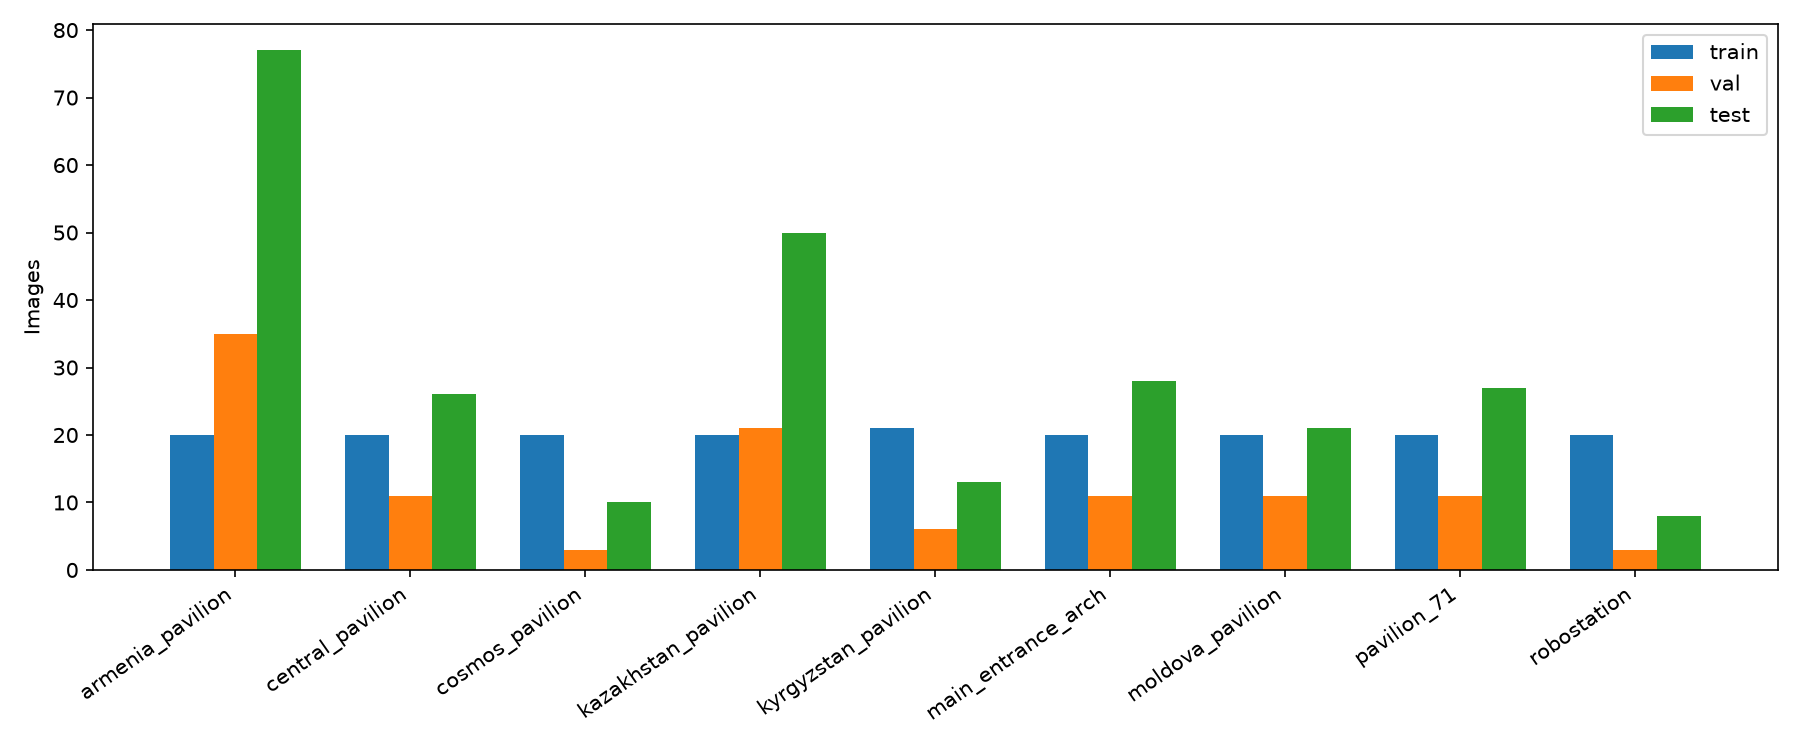

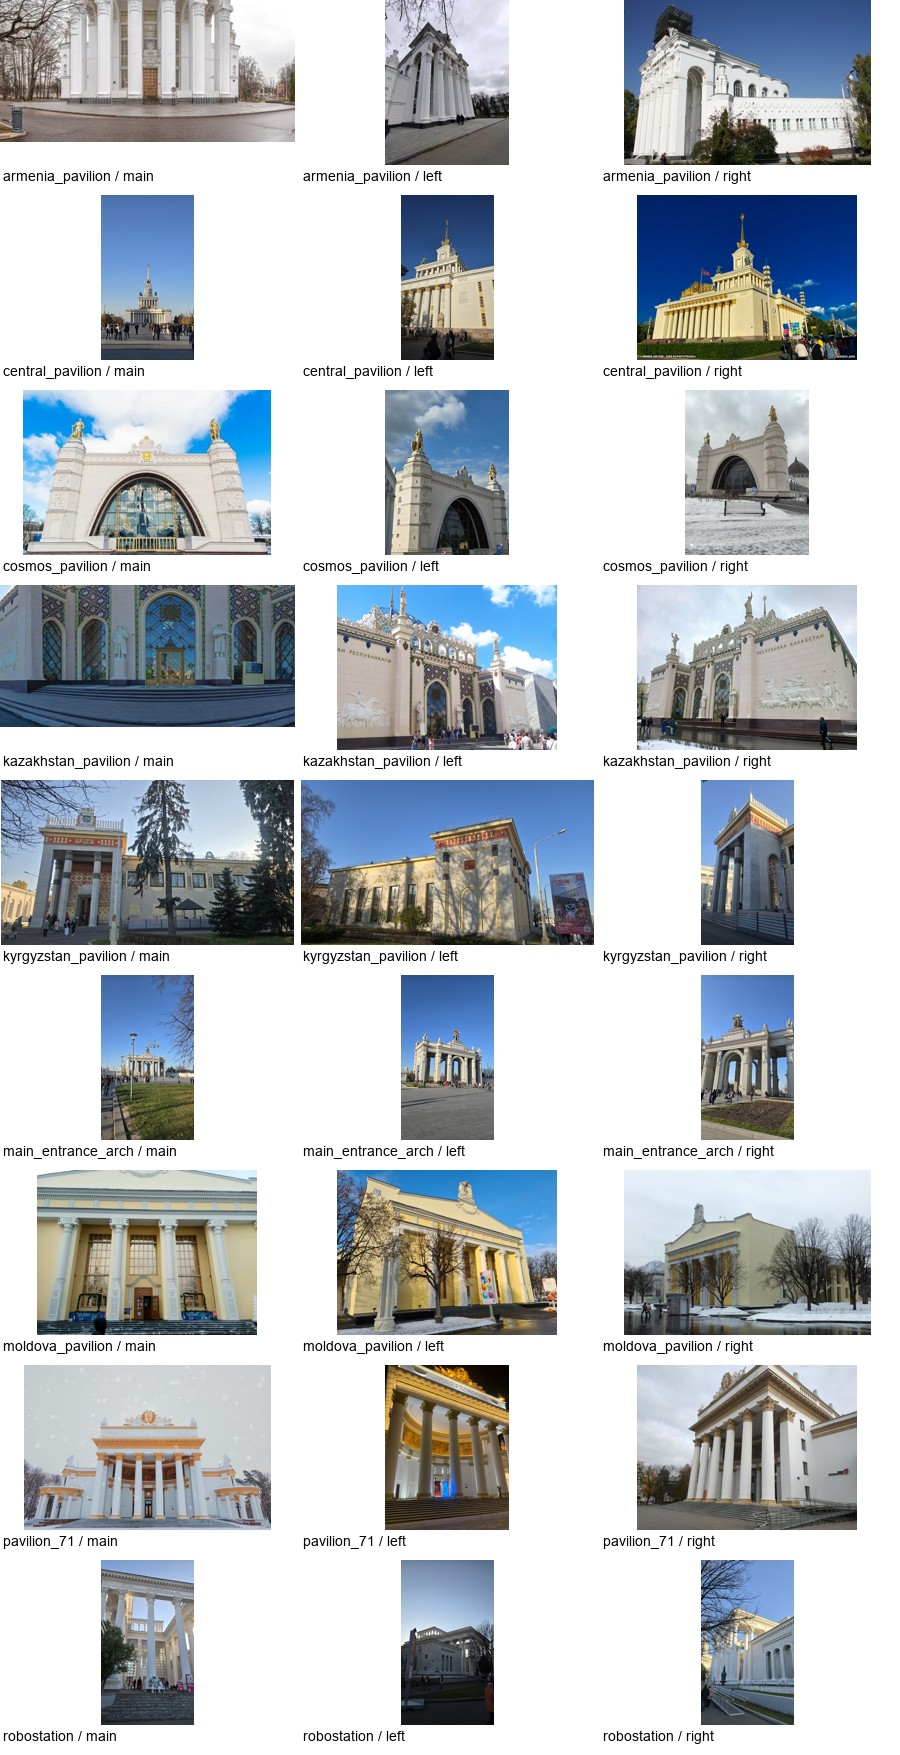

In [2]:
table([load(REPORT/'preflight.json')], ['classes','train_pool','val','test'])
mapping = load(DATA/'class_mapping.json')
table([{'poi_id':p, 'class_index':i} for p,i in mapping.items()])
table([r for r in read(REPORT/'train_coverage.csv') if r['seed']=='42'])
table(read(REPORT/'split_coverage.csv'))
display(Image(filename=str(REPORT/'figures/dataset_counts.png')))
display(Image(filename=str(REPORT/'figures/training_examples.jpg')))

Освещение, масштаб и перекрытия не везде удалось уравнять между О и Р. Ниже показан остаточный дисбаланс TV: чем меньше значение, тем ближе условия. Поэтому результат относится к подборкам фото, а влияние одного ракурса полностью отделить нельзя.

Для части контрольных снимков неизвестна история съёмки. Это внутренняя оценка: полную независимость съёмок подтвердить нельзя.

In [3]:
balance = read(REPORT/'balance.csv')
table([{'poi_id':p, **{k:max(float(r[k]) for r in balance if r['poi_id']==p) for k in ['TV_illumination','TV_scale','TV_occlusion']}} for p in mapping])

poi_id,TV_illumination,TV_scale,TV_occlusion
armenia_pavilion,0.2500,0.2500,0.1667
central_pavilion,0.1667,0.1667,0.1667
cosmos_pavilion,0.3333,0.2500,0.2500
kazakhstan_pavilion,0.0000,0.1667,0.0833
kyrgyzstan_pavilion,0.0000,0.0000,0.0000
main_entrance_arch,0.0833,0.0833,0.0833
moldova_pavilion,0.0833,0.3333,0.5000
pavilion_71,0.1667,0.2500,0.0833
robostation,0.1667,0.1667,0.1667


## Что проверяю

Основная метрика — Macro-F1 по девяти объектам. Сначала усредняю результаты трёх seed, затем считаю:

- GО = F1(Large, О) − F1(Small, О).
- GР = F1(Large, Р) − F1(Small, Р).
- C = GО − GР.

Для подтверждения нужны оба условия: нижняя граница 95% интервала C ≥ 3 п.п. и верхняя граница GР ≤ 3 п.п. Одних средних значений недостаточно.

## Обучение

Всего 12 новых моделей: Small и Large, О и Р, seed 42, 43 и 44. Начальные веса — ImageNet V1. Старые обученные модели не использую.

RGB 224 × 224, FP32, обучение всех слоёв и BatchNorm. AdamW: lr = 0.0001, weight decay = 0.0001, batch = 32. Бюджет — 20 эпох, выборка с балансировкой классов, из аугментаций только изменение цвета. Сохраняю эпоху с лучшим validation Macro-F1; при равенстве выбираю более раннюю.

In [4]:
config = load(DATA/'config.json')
table([{'параметр':k, 'значение':v} for k,v in config.items()])
table([{'architecture':k, **v} for k,v in load(REPORT/'pretraining_weights.json').items()])
print(load(REPORT/'pilot_decision.json')['reason'])
table(read(REPORT/'pilot_review.csv'))

параметр,значение
run_id,h1_20261104_v1
epochs,20
batch_size,32
learning_rate,0.0001
weight_decay,0.0001
seeds,"[42, 43, 44]"
threads,4
input_size,224
pretraining,IMAGENET1K_V1
batchnorm,all_train


architecture,identifier,file,sha256
small,IMAGENET1K_V1,mobilenet_v3_small-047dcff4.pth,047dcff4addef86ea5bc2eff13c9614dc11f47ab1160d0a71a25e7db994f4e1f
large,IMAGENET1K_V1,mobilenet_v3_large-8738ca79.pth,8738ca797c879b547d18bbd15da5736ff2557b2036a9af72225393ca61759a04


Сохраняем заранее заданный бюджет 20 эпох для всех конфигураций. Large обучилась на train: итоговый loss 0,0415 в О и 0,0531 в Р. В режиме О лучший validation Macro-F1 достигнут на 15-й эпохе. В Р и у Small validation ещё меняется к 20-й эпохе, поэтому полная сходимость не заявляется. Результат относится к сравнению при фиксированном бюджете. Test не использовался при этом решении.


config,epochs,best_epoch,best_val_f1,last_loss,tail_gain,warning
small_O,20,20,0.4478534237154927,0.2097515430715349,0.0630603593525359,True
large_O,20,15,0.5514655880754952,0.041496403239391466,0.007038746068495971,False
small_R,20,20,0.542385318855907,0.2999937159043771,0.08347095621127176,True
large_R,20,20,0.6618039757349146,0.05307251325360051,0.06157882657359526,True


Первые четыре обучения входят в итоговые 12. После пилота оставлен одинаковый бюджет 20 эпох. У части моделей validation ещё меняется к концу обучения, поэтому полную сходимость не заявляю. Test открыт после завершения всех 12 запусков.

### Seed 42

Показываю выбор checkpoint, изменение loss и validation Macro-F1. Полные значения всех 20 эпох сохранены в history.csv каждого запуска.

small_O, seed 42


epoch,macro_f1,accuracy
20,0.4479,0.5625


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


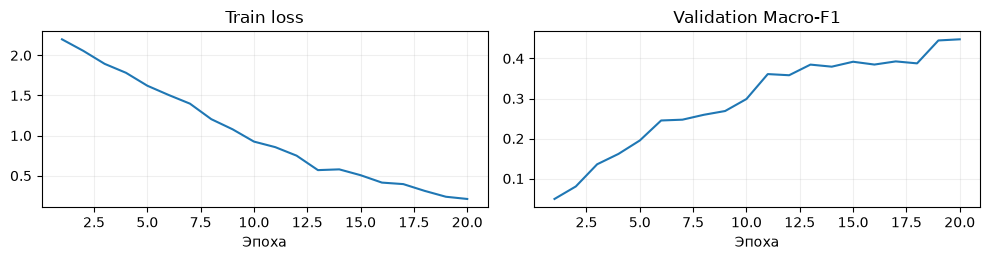

epoch,train_loss,seconds,macro_f1,accuracy
16,0.4137335960511808,3.4711448999987624,0.3847930643629568,0.49107142857142855
17,0.39498663169366344,3.855396800001472,0.39269010445481034,0.5
18,0.3108589704389925,3.5490726999996696,0.38778141936036675,0.5178571428571429
19,0.2372621794541677,3.869633399997838,0.44504990914727227,0.5446428571428571
20,0.2097515430715349,4.263413299999229,0.4478534237154927,0.5625


In [5]:
run = MODELS/'runs/small_O_seed42'
print('small_O, seed 42')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

large_O, seed 42


epoch,macro_f1,accuracy
15,0.5515,0.5804


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


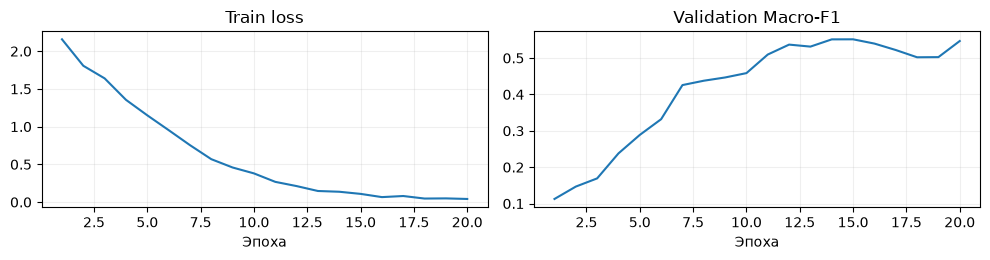

epoch,train_loss,seconds,macro_f1,accuracy
16,0.06606816252072652,9.791483900000458,0.5397451526761871,0.5714285714285714
17,0.08052678406238556,9.777329500000633,0.5220658970658971,0.5714285714285714
18,0.04695718128372122,9.693981199998234,0.5020986676159089,0.5535714285714286
19,0.04906199844899001,9.7450319999989,0.5025102373939583,0.5535714285714286
20,0.041496403239391466,9.72671629999968,0.546783898744683,0.5892857142857143


In [6]:
run = MODELS/'runs/large_O_seed42'
print('large_O, seed 42')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

small_R, seed 42


epoch,macro_f1,accuracy
20,0.5424,0.5357


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


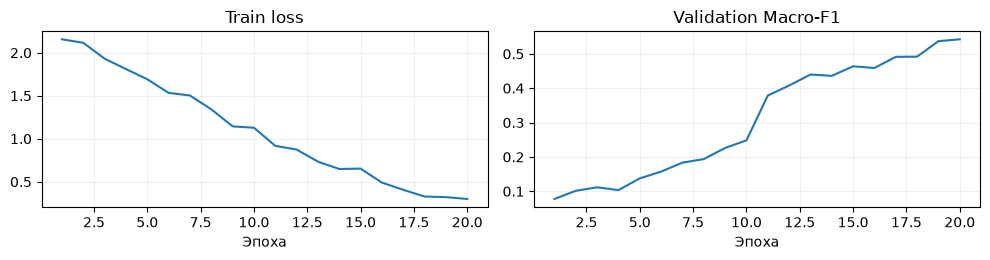

epoch,train_loss,seconds,macro_f1,accuracy
16,0.4903837861838164,3.511915899998712,0.45891436264463525,0.49107142857142855
17,0.40627813559991344,3.6432524000010744,0.4913415005413293,0.5267857142857143
18,0.32820896749143247,3.8325791999996,0.4919177365117798,0.5267857142857143
19,0.3213040089165723,3.5795388000005914,0.5369700602608454,0.5357142857142857
20,0.2999937159043771,3.7094507000001613,0.542385318855907,0.5357142857142857


In [7]:
run = MODELS/'runs/small_R_seed42'
print('small_R, seed 42')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

large_R, seed 42


epoch,macro_f1,accuracy
20,0.6618,0.5804


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


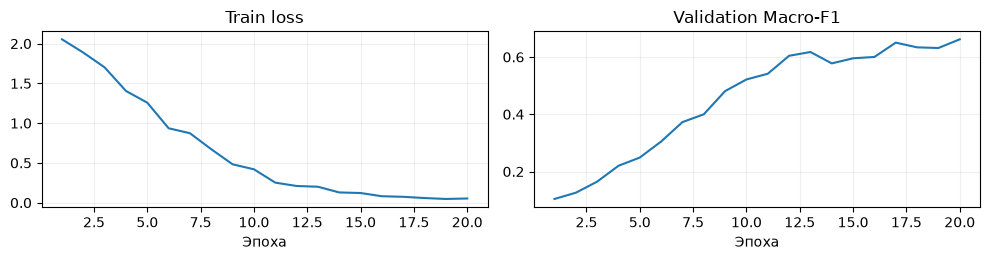

epoch,train_loss,seconds,macro_f1,accuracy
16,0.08137073119481404,9.335177400000248,0.6002251491613193,0.5982142857142857
17,0.07427086708722291,9.711697300001106,0.6502251491613193,0.6071428571428571
18,0.058577296082620266,9.536498399997072,0.6337660866657318,0.5803571428571429
19,0.047078763169270975,9.816901199999847,0.6314755340857182,0.5714285714285714
20,0.05307251325360051,9.717553000002226,0.6618039757349146,0.5803571428571429


In [8]:
run = MODELS/'runs/large_R_seed42'
print('large_R, seed 42')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

### Seed 43

Показываю выбор checkpoint, изменение loss и validation Macro-F1. Полные значения всех 20 эпох сохранены в history.csv каждого запуска.

small_O, seed 43


epoch,macro_f1,accuracy
18,0.4597,0.5893


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


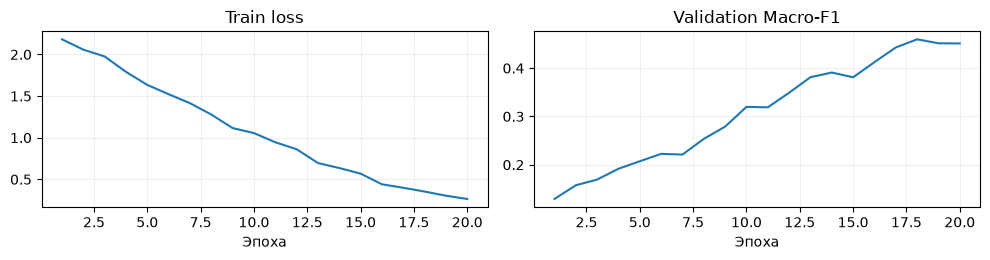

epoch,train_loss,seconds,macro_f1,accuracy
16,0.4403458303875393,3.5853747999972256,0.41234811886985795,0.5535714285714286
17,0.39871974454985726,3.68843729999935,0.4427898993116384,0.5714285714285714
18,0.35352796426525823,3.833599999998114,0.45967366015162575,0.5892857142857143
19,0.3030667614053797,3.937421299997368,0.4514699897052839,0.5803571428571429
20,0.2642644941806793,3.616454799997882,0.4511212643565585,0.5714285714285714


In [9]:
run = MODELS/'runs/small_O_seed43'
print('small_O, seed 43')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

large_O, seed 43


epoch,macro_f1,accuracy
20,0.5555,0.6071


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


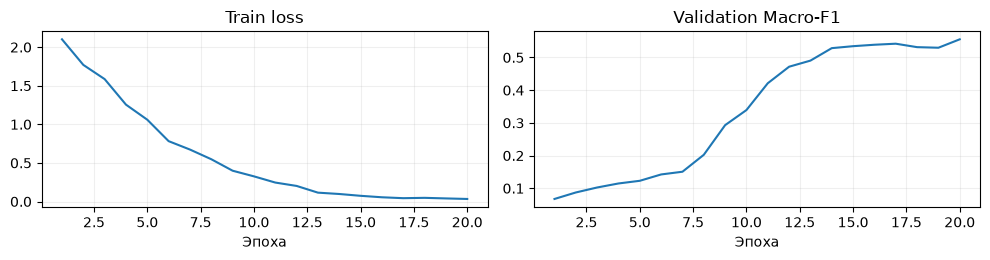

epoch,train_loss,seconds,macro_f1,accuracy
16,0.0548740777152556,9.520643700001528,0.5389421233959049,0.5982142857142857
17,0.04322323561818511,9.593827300002886,0.5421286611689088,0.5982142857142857
18,0.04754606192862546,10.464918599998782,0.5315807247301584,0.5982142857142857
19,0.040006757610374026,10.10963620000257,0.5298031142568957,0.5982142857142857
20,0.033036801826070855,9.64384059999793,0.5555424880205856,0.6071428571428571


In [10]:
run = MODELS/'runs/large_O_seed43'
print('large_O, seed 43')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

small_R, seed 43


epoch,macro_f1,accuracy
20,0.4889,0.5714


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


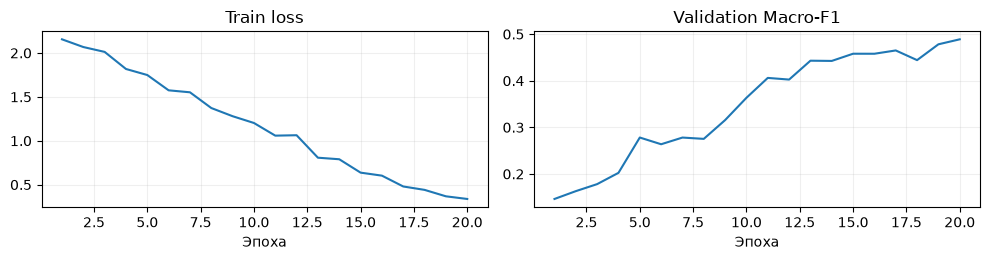

epoch,train_loss,seconds,macro_f1,accuracy
16,0.6027396100538748,3.796517099999619,0.4579438846234712,0.5446428571428571
17,0.4792959425184462,3.7347241999996186,0.46502618593628575,0.5535714285714286
18,0.44061670259193136,3.6068113000001176,0.4442487081974227,0.5535714285714286
19,0.36734071042802596,3.509585199997673,0.47819806728587644,0.5714285714285714
20,0.33713739337744536,3.461803999998665,0.4889072952956571,0.5714285714285714


In [11]:
run = MODELS/'runs/small_R_seed43'
print('small_R, seed 43')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

large_R, seed 43


epoch,macro_f1,accuracy
15,0.6433,0.6250


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


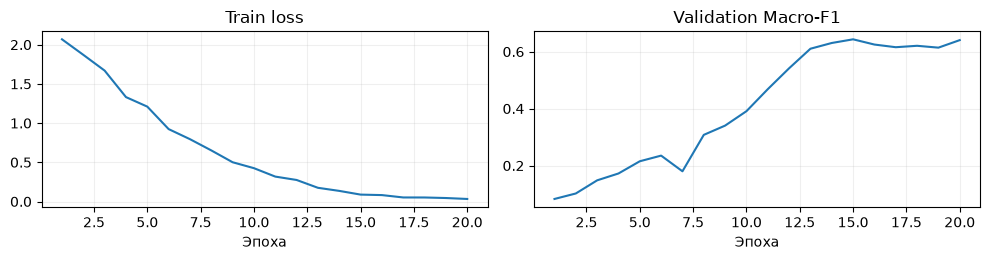

epoch,train_loss,seconds,macro_f1,accuracy
16,0.08190393061549575,9.890096600000106,0.6249759012916907,0.5982142857142857
17,0.051675571611634004,9.633472400000755,0.6156347379257596,0.5892857142857143
18,0.051373297141657934,9.658047400000214,0.6206186028167452,0.5982142857142857
19,0.04450031162963973,9.883828599999106,0.6140960704321439,0.5803571428571429
20,0.03252478164655191,9.858834400001797,0.6405102982395269,0.6160714285714286


In [12]:
run = MODELS/'runs/large_R_seed43'
print('large_R, seed 43')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

### Seed 44

Показываю выбор checkpoint, изменение loss и validation Macro-F1. Полные значения всех 20 эпох сохранены в history.csv каждого запуска.

small_O, seed 44


epoch,macro_f1,accuracy
19,0.5041,0.6071


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


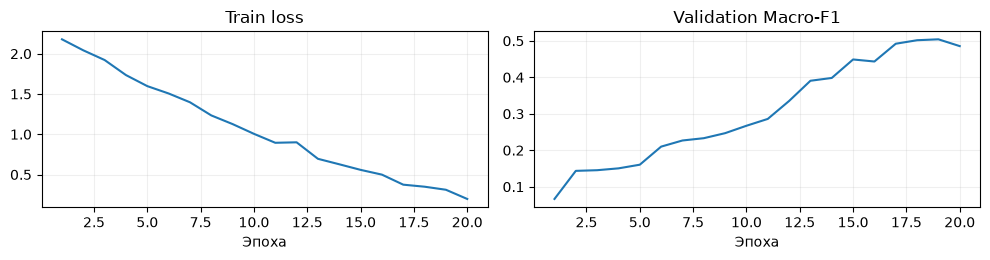

epoch,train_loss,seconds,macro_f1,accuracy
16,0.4990371311152423,3.4838938000029884,0.4432935047627702,0.5535714285714286
17,0.3744436071978675,3.4467578000003414,0.49200401071746097,0.5803571428571429
18,0.34915818991484465,3.540448400002788,0.501623643845866,0.5892857142857143
19,0.3113587862915463,3.53261940000084,0.504118425322297,0.6071428571428571
20,0.19706705378161538,3.517722099997627,0.48547710495683877,0.5803571428571429


In [13]:
run = MODELS/'runs/small_O_seed44'
print('small_O, seed 44')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

large_O, seed 44


epoch,macro_f1,accuracy
20,0.5365,0.5982


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


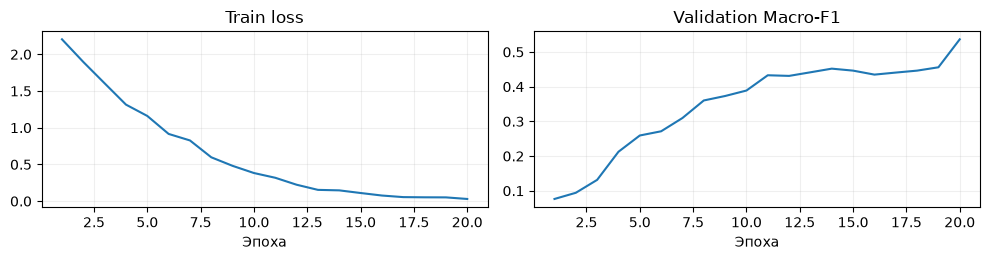

epoch,train_loss,seconds,macro_f1,accuracy
16,0.07639178136984508,10.389625199997681,0.4347629863969733,0.5357142857142857
17,0.05479457284565325,10.227833900000405,0.4406373769011773,0.5357142857142857
18,0.05214818373874382,10.527418800000305,0.4462363530883888,0.5446428571428571
19,0.05115833988896123,10.218944100000954,0.4558520784935879,0.5535714285714286
20,0.029636778075385978,9.963312300002144,0.536489106499037,0.5982142857142857


In [14]:
run = MODELS/'runs/large_O_seed44'
print('large_O, seed 44')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

small_R, seed 44


epoch,macro_f1,accuracy
20,0.5770,0.6518


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


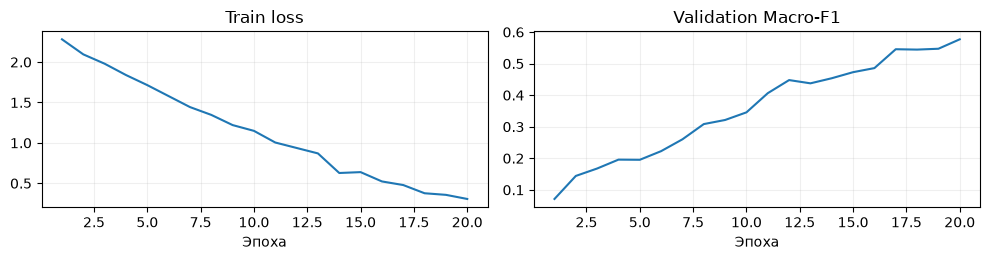

epoch,train_loss,seconds,macro_f1,accuracy
16,0.5228784305078013,3.5191091999986384,0.4858126673629073,0.5982142857142857
17,0.4781836779029281,3.450373600000603,0.5455983878855033,0.6339285714285714
18,0.37661128022052626,3.5066503999987617,0.5444365418633588,0.6428571428571429
19,0.35687444717795763,3.9662357999986853,0.5471174810169622,0.6428571428571429
20,0.30593983442695055,3.557730399999855,0.577008083490391,0.6517857142857143


In [15]:
run = MODELS/'runs/small_R_seed44'
print('small_R, seed 44')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

large_R, seed 44


epoch,macro_f1,accuracy
20,0.6567,0.6429


Поля лога: epoch, train_loss, seconds, macro_f1, accuracy


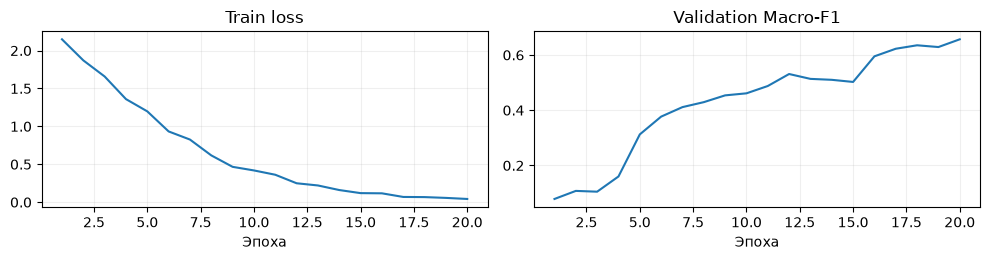

epoch,train_loss,seconds,macro_f1,accuracy
16,0.11693364823306049,9.418909400003031,0.5951093241168096,0.5982142857142857
17,0.06910468610348525,9.92483120000179,0.6226022082337347,0.6160714285714286
18,0.06706274659545333,9.987330799998745,0.6351290676789768,0.625
19,0.05663127341756114,9.848822100000689,0.6287550114644307,0.625
20,0.042546242475509644,10.137258099999599,0.6567478278782998,0.6428571428571429


In [16]:
run = MODELS/'runs/large_R_seed44'
print('large_R, seed 44')
table([load(run/'selection.json')])
history = read(run/'history.csv')
print('Поля лога:', ', '.join(history[0]))
fig, axes = plt.subplots(1, 2, figsize=(10, 2.7))
epochs = [int(r['epoch']) for r in history]
loss_key = next(k for k in history[0] if 'loss' in k and 'train' in k)
f1_key = 'macro_f1'
axes[0].plot(epochs, [float(r[loss_key]) for r in history]); axes[0].set_title('Train loss')
axes[1].plot(epochs, [float(r[f1_key]) for r in history]); axes[1].set_title('Validation Macro-F1')
for ax in axes: ax.set_xlabel('Эпоха'); ax.grid(alpha=.2)
fig.tight_layout(); plt.show(); plt.close(fig)
table(history[-5:])

## Результаты на test

Средние значения и SD рассчитаны по трём seed. SD рассчитано с ddof = 1, показывает разброс запусков и не является доверительным интервалом.

In [17]:
summary = read(REPORT/'test_summary.csv')
metrics = read(REPORT/'test_metrics.csv')
table([{**{k:(r[k] if k=='config' else float(r[k])) for k in r}, 'accuracy_SD':float(np.std([float(t['accuracy']) for t in metrics if t['config']==r['config']], ddof=1))} for r in summary])
table(read(REPORT/'test_metrics.csv'))
table(read(REPORT/'per_seed_contrasts.csv'))
point = load(REPORT/'inference.json')['point']
table([{'показатель':k, 'п.п.':100*point[k]} for k in ['G_O','G_R','C','small_gain','large_gain']])

config,macro_f1_mean,macro_f1_SD,accuracy_mean,accuracy_SD
small_O,0.5433,0.0181,0.6256,0.0097
large_O,0.6192,0.0162,0.6436,0.0273
small_R,0.5729,0.0223,0.6218,0.0370
large_R,0.6064,0.0207,0.6385,0.0520


config,seed,best_epoch,macro_f1,accuracy
small_O,42,20,0.5641174595670535,0.6346153846153846
small_O,43,18,0.5343857068450564,0.6269230769230769
small_O,44,19,0.5312698186805712,0.6153846153846154
large_O,42,15,0.6061989389001773,0.6384615384615384
large_O,43,20,0.613925135416971,0.6192307692307693
large_O,44,20,0.6373696204844664,0.6730769230769231
small_R,42,20,0.5983529696588668,0.5884615384615385
small_R,43,20,0.556674763649521,0.6153846153846154
small_R,44,20,0.5637663403127449,0.6615384615384615
large_R,42,20,0.5851157050322997,0.5846153846153846


seed,G_O,G_R,C
42,0.042081479333123784,-0.013237264626567047,0.05531874395969083
43,0.07953942857191465,0.050892077986698925,0.028647350585215725
44,0.10609980180389522,0.0627833574983464,0.04331644430554882


показатель,п.п.
G_O,7.5907
G_R,3.3479
C,4.2428
small_gain,2.9674
large_gain,-1.2754


### Ошибки по объектам и ракурсам

Матрицы ошибок и F1 по объектам усреднены по трём seed. В срезах остаются все девять классов ответа. В проверке leave-one-POI-out исключаю один объект из оценки и усредняю F1 по восьми оставшимся; заново модели не обучаю.

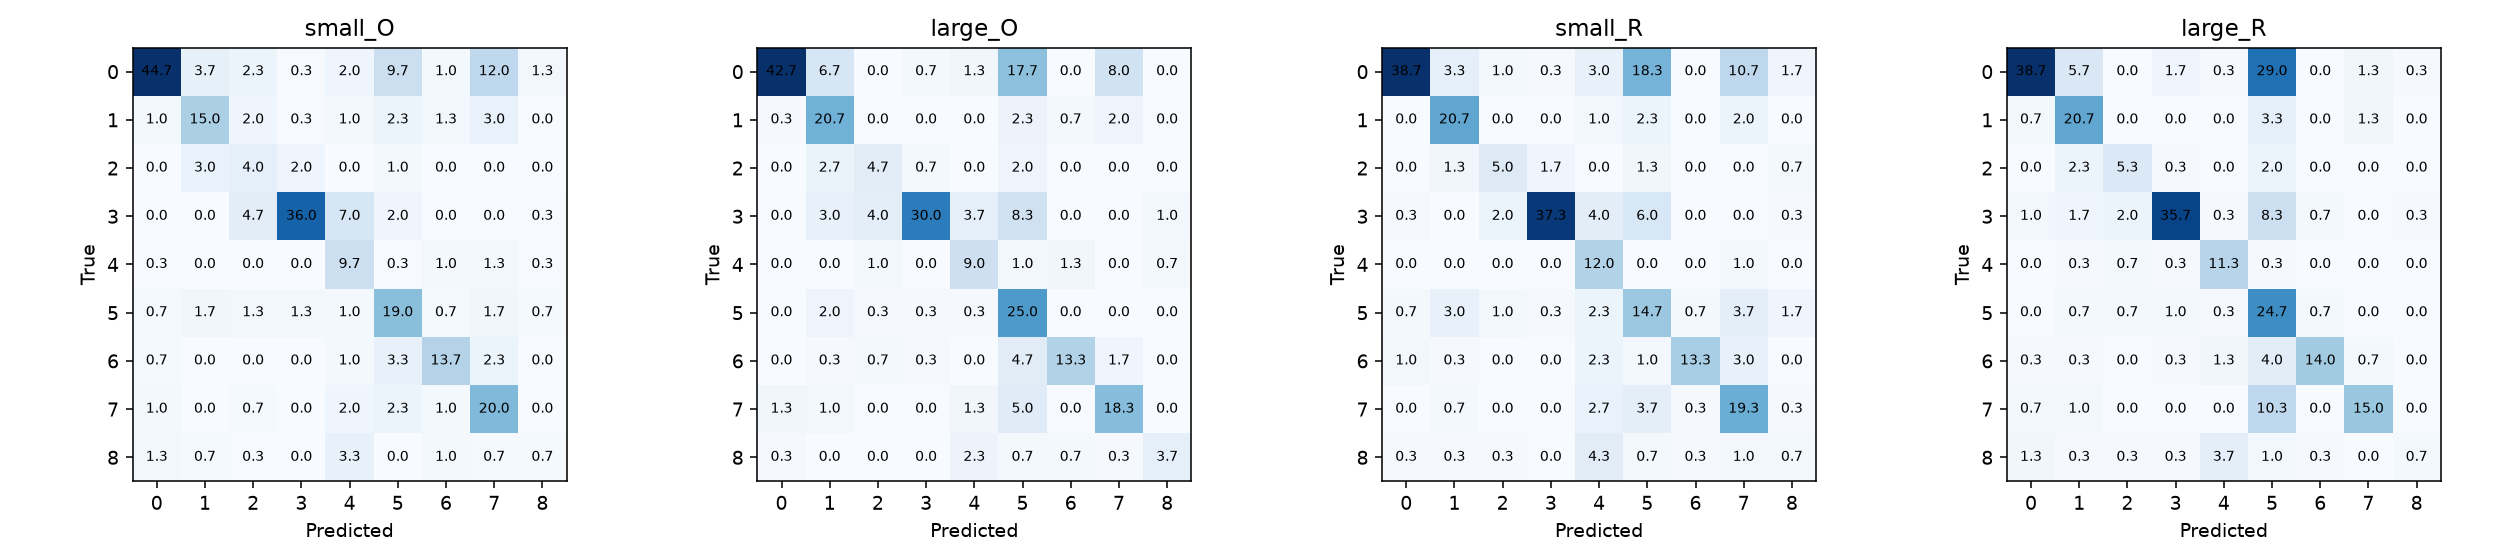

poi_id,small_O,large_O,small_R,large_R
armenia_pavilion,0.7050,0.6981,0.6376,0.6268
central_pavilion,0.5996,0.6750,0.7555,0.7098
cosmos_pavilion,0.3509,0.4566,0.5527,0.5698
kazakhstan_pavilion,0.7996,0.7290,0.8328,0.7918
kyrgyzstan_pavilion,0.4827,0.5665,0.5799,0.7474
main_entrance_arch,0.5699,0.5326,0.3844,0.4465
moldova_pavilion,0.6760,0.7179,0.7468,0.7621
pavilion_71,0.5877,0.6491,0.5740,0.6627
robostation,0.1179,0.5476,0.0926,0.1407


Средний recall по объектам


poi_id,small_O,large_O,small_R,large_R
armenia_pavilion,0.5801,0.5541,0.5022,0.5022
central_pavilion,0.5769,0.7949,0.7949,0.7949
cosmos_pavilion,0.4000,0.4667,0.5000,0.5333
kazakhstan_pavilion,0.7200,0.6000,0.7467,0.7133
kyrgyzstan_pavilion,0.7436,0.6923,0.9231,0.8718
main_entrance_arch,0.6786,0.8929,0.5238,0.8810
moldova_pavilion,0.6508,0.6349,0.6349,0.6667
pavilion_71,0.7407,0.6790,0.7160,0.5556
robostation,0.0833,0.4583,0.0833,0.0833


config,viewpoint,n,macro_f1,accuracy
large_O,left,37.0000,0.5635,0.6396
large_O,main,154.0000,0.6564,0.6861
large_O,right,66.0000,0.4275,0.5354
large_O,undetermined,3.0000,0.1037,0.8889
large_R,left,37.0000,0.7057,0.8108
large_R,main,154.0000,0.5552,0.6169
large_R,right,66.0000,0.4336,0.5758
large_R,undetermined,3.0000,0.1111,1.0000
small_O,left,37.0000,0.5230,0.6306
small_O,main,154.0000,0.5338,0.6277


excluded_poi,classes_evaluated,predicted_classes,C,G_R
armenia_pavilion,8,9,0.04834298011372614,0.03540753867857146
central_pavilion,8,9,0.025676360828953675,0.04341129610296727
cosmos_pavilion,8,9,0.03501352858394147,0.03541473688054272
kazakhstan_pavilion,8,9,0.0656006439353225,0.04449244865904715
kyrgyzstan_pavilion,8,9,0.06310529500339719,0.018377362414112548
main_entrance_arch,8,9,0.06273281261916297,0.019413260480571532
moldova_pavilion,8,9,0.0468823699372111,0.03399263118786063
pavilion_71,8,9,0.0512252246048864,0.026375749568384992
robostation,8,9,-0.008311627482793274,0.03795618593405059


In [18]:
display(Image(filename=str(REPORT/'figures/confusion_matrices.png')))
per_poi = read(REPORT/'per_poi_metrics.csv')
table([{'poi_id':p, **{k:np.mean([float(r['f1']) for r in per_poi if r['poi_id']==p and r['config']==k]) for k in h1.CONFIGS}} for p in mapping])
print('Средний recall по объектам')
table([{'poi_id':p, **{k:float(np.mean([float(r['recall']) for r in per_poi if r['poi_id']==p and r['config']==k])) for k in h1.CONFIGS}} for p in mapping])
views = read(REPORT/'viewpoint_slices.csv')
groups = sorted(set((r['config'],r['viewpoint']) for r in views))
table([{'config':k, 'viewpoint':v, **{m:float(np.mean([float(r[m]) for r in views if r['config']==k and r['viewpoint']==v])) for m in ['n','macro_f1','accuracy']}} for k,v in groups])
table(read(REPORT/'leave_one_poi_out.csv'))

### Устойчивость результата

Дополнительно сравниваю результаты трёх seed и проверяю, как меняется вывод при исключении одного объекта из оценки. Это описательный анализ, добавленный после основного расчёта. Он показывает разброс на имеющихся данных и не заменяет проверку по доверительным интервалам.

In [19]:
table([{k:(v if k=='metric' else float(v)) for k,v in r.items()} for r in read(REPORT/'seed_stability.csv')])
print('Все значения таблицы — в процентных пунктах.')
print(load(REPORT/'stability_summary.json'))

metric,mean_pp,SD_pp,min_pp,max_pp
G_O,7.5907,3.2163,4.2081,10.6100
G_R,3.3479,4.0892,-1.3237,6.2783
C,4.2428,1.3358,2.8647,5.5319


Все значения таблицы — в процентных пунктах.
{'seed_count': 3, 'C_positive_seeds': 3, 'both_point_thresholds_seeds': 1, 'loo_C_positive': 8, 'loo_total': 9, 'loo_C_min_pp': -0.8311627482793275, 'loo_C_max_pp': 6.56006439353225, 'analysis': 'descriptive_post_hoc', 'confidence_intervals': False, 'original_hypothesis_test_replaced': False}


Сокращение разрыва C положительное при всех трёх seed. Но оба точечных условия выполняются вместе только в одном из трёх запусков. В проверке без одного объекта C положительное в восьми из девяти случаев. Без «Робостанции» C = −0.83 п.п., поэтому общий вывод чувствителен к составу объектов.

Исходный план предусматривал 5000 парных bootstrap-повторов по сеансам съёмки. У 225 тестовых фото сеанс неизвестен, поэтому такие интервалы не рассчитаны. Результаты трёх seed и проверки по объектам показывают другие стороны устойчивости; статистического подтверждения исходной гипотезы они не дают.

## Экспорт и скорость

Для сравнения заранее выбраны модели Р с seed 42. Обе экспортированы в FP32 TorchScript. Классы после экспорта совпали на всём test.

Замеры сделаны на CPU компьютера: 20 прогревов, затем 3 серии по 100 запусков с чередованием моделей. Отдельно показан проход модели и полный путь с чтением и подготовкой фото. На телефоне замеров нет.

In [20]:
table(read(REPORT/'export_parity.csv'))
table(read(REPORT/'resources.csv'))
table([{'параметр':k,'значение':v} for k,v in load(REPORT/'mobile_status.json').items()])

architecture,max_logit_difference,predictions_equal,file_bytes,parameters,dtype,format
small,3.993511199951172e-05,True,6119031,1527081,float32,TorchScript
large,1.049041748046875e-05,True,16846069,4213561,float32,TorchScript


architecture,repeat,forward_p50_ms,forward_p95_ms,full_p50_ms,full_p95_ms,warmups,measurements,threads,device,dtype,runtime,scope
small,1,8.477449999190867,9.658469997702923,34.192149998489185,41.923450000103905,20,100,4,Windows CPU,float32,TorchScript,file decode + RGB/pad/normalize + model; excludes camera and network
large,1,16.751199998907396,19.294310001532722,41.836399999738205,50.62556000011681,20,100,4,Windows CPU,float32,TorchScript,file decode + RGB/pad/normalize + model; excludes camera and network
large,2,16.634050001812284,19.473529997776495,42.12905000167666,50.77847499924246,20,100,4,Windows CPU,float32,TorchScript,file decode + RGB/pad/normalize + model; excludes camera and network
small,2,8.262299999842071,9.068710000246938,33.46149999924819,41.17101500014542,20,100,4,Windows CPU,float32,TorchScript,file decode + RGB/pad/normalize + model; excludes camera and network
small,3,8.263150000857422,9.412814998722752,33.553350000147475,40.774209998380684,20,100,4,Windows CPU,float32,TorchScript,file decode + RGB/pad/normalize + model; excludes camera and network
large,3,16.804300001240335,18.97567499872821,42.131600001084735,50.02378499975747,20,100,4,Windows CPU,float32,TorchScript,file decode + RGB/pad/normalize + model; excludes camera and network


параметр,значение
phone_measurements,False
product_quality_threshold,None
product_p95_budget,None
release_recommendation,False


## Вывод

В режиме Р средний Macro-F1 Small — 0.5729, Large — 0.6064. Разрыв GР — 3.35 п.п., сокращение разрыва C — 4.24 п.п. Среднее отставание Small превышает заданные 3 п.п. Подтверждения составной гипотезы на этих данных не получено.

Small прибавила 2.97 п.п., а Large потеряла 1.28 п.п. Значит, разрыв уменьшился в том числе из-за ухудшения Large.

Вывод относится к этим девяти объектам и бюджету 20 эпох. Для выбора модели приложения нужны требования к качеству и p95, а также замеры на телефоне.

## Как повторить

Код эксперимента — scripts/h1_research.py. Порядок команд: prepare с новым bundle и run_id, pilot, проверка пилота, main, evaluate, notebook. Конфигурация и манифесты этого запуска сохранены в data/annotations/h1_20261104_v1.

После открытия test настройки этого запуска не меняю. Новый эксперимент запускается отдельно. Графики и таблицы этого ноутбука построены по сохранённым логам, checkpoint и предсказаниям.